In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Data Collection

In [2]:
df = pd.read_csv(r"C:\Users\SAHU\OneDrive\Desktop\Data Analytic\Internship - IIM SKIlLS\Intership 30-10-2026\2nd Project\IBM HR-Employee-Attrition.csv")

# Data Assessing

In [3]:
# Data profiling
df.head()
df.tail()
df.shape
df.info()
df.describe(include='all')

# for null values
df.isna().sum()
df.isna().sum()[df.isna().sum()>0]

# For outliers

# Select relevant numerical columns for outlier assessment
outlier_cols = [
    "Age",
    "DistanceFromHome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

# Calculate IQR-based outlier limits and counts
outlier_results = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    )

    outlier_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_Percentage": outlier_mask.mean() * 100
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report.round(2))

df[df['TotalWorkingYears']<0]
df[df['YearsAtCompany']<0]
df[df['YearsInCurrentRole']<0]
df[df['YearsSinceLastPromotion']<0]
df[df['YearsWithCurrManager']<0]

# For duplicates
df[df.duplicated()]

# For inconsistency data
col = ['Attrition','BusinessTravel','Department','EducationField','Gender','JobRole','MaritalStatus','Over18', 'OverTime']
for c in col:
    print(df[c].value_counts())
    print('-'*50)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

,Column,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percentage
0,Age,30.0,43.0,13.0,10.5,62.5,0,0.00
1,DistanceFromHome,2.0,14.0,12.0,-16.0,32.0,0,0.00
2,TotalWorkingYears,6.0,15.0,9.0,-7.5,28.5,63,4.29
3,YearsAtCompany,3.0,9.0,6.0,-6.0,18.0,104,7.07
4,YearsInCurrentRole,2.0,7.0,5.0,-5.5,14.5,21,1.43
5,YearsSinceLastPromotion,0.0,3.0,3.0,-4.5,7.5,107,7.28
6,YearsWithCurrManager,2.0,7.0,5.0,-5.5,14.5,14,0.95


Attrition
No     1233
Yes     237
Name: count, dtype: int64
--------------------------------------------------
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
--------------------------------------------------
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
--------------------------------------------------
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
--------------------------------------------------
Gender
Male      882
Female    588
Name: count, dtype: int64
--------------------------------------------------
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager             

# Phase 1: Data Profiling and Data Quality Assessment — Conclusion

## 1. Dataset Overview

- The dataset contains **1,470 employee records and 35 columns**.
- It consists of **26 integer-type columns and 9 object-type columns**.
- The dataset includes employee demographics, job roles, compensation, satisfaction, work experience, and attrition information.
- The `head()` and `tail()` methods were used to inspect the first and last five records.
- The `shape` attribute confirmed the dataset dimensions, while `info()` displayed column data types and non-null counts.
- The `describe(include='all')` method generated descriptive statistics for numerical and categorical columns.

## 2. Missing Value Assessment

- The `isna().sum()` method identified **zero missing values across all 35 columns**.
- The expression `df.isna().sum()[df.isna().sum() > 0]` filters and displays only columns containing missing values.
- The assessment confirmed that missing-value imputation is not required.
- Additional validation may still be necessary to identify invalid values or inconsistencies that are not represented as null values.

## 3. Outlier Assessment Using the IQR Method

- The Interquartile Range (IQR) method was applied to seven numerical columns: `Age`, `DistanceFromHome`, `TotalWorkingYears`, `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, and `YearsWithCurrManager`.
- The first quartile (Q1) was calculated using `quantile(0.25)`, while the third quartile (Q3) was calculated using `quantile(0.75)`.
- The IQR was calculated as `Q3 - Q1`.
- The lower and upper outlier limits were calculated using `Q1 - 1.5 * IQR` and `Q3 + 1.5 * IQR`, respectively.
- The analysis detected the following potential outliers:

  - `Age`: 0 outliers (0.00%).
  - `DistanceFromHome`: 0 outliers (0.00%).
  - `TotalWorkingYears`: 63 outliers (4.29%).
  - `YearsAtCompany`: 104 outliers (7.07%).
  - `YearsInCurrentRole`: 21 outliers (1.43%).
  - `YearsSinceLastPromotion`: 107 outliers (7.28%).
  - `YearsWithCurrManager`: 14 outliers (0.95%).

- `YearsSinceLastPromotion` contains the highest number of IQR-flagged observations, followed by `YearsAtCompany`.
- No outliers were detected in `Age` or `DistanceFromHome` using the selected IQR thresholds.
- These observations are statistical outliers and are not necessarily data-entry errors.
- Potential outliers should be investigated before treatment because unusually long employment periods or promotion gaps may represent legitimate employee histories.
- There is no need to be worry for those columns which contains outliers because as per the nature of these columns there could be high value but could never the value in negative.

## 4. Invalid Negative Tenure Values

- Boolean conditions such as `df[df['TotalWorkingYears'] < 0]` were used to identify negative values in selected tenure columns.
- The same validation was performed for `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, and `YearsWithCurrManager`.
- All five checks returned zero records, indicating that no negative values were detected in these columns.
- The logical condition `YearsAtCompany <= TotalWorkingYears` was also validated.
- No records violated this condition, indicating consistency between company tenure and total work experience for the checked rule.

## 5. Duplicate Record Assessment

- The `df.duplicated()` method was used to identify exact duplicate rows.
- The expression `df.duplicated().sum()` can be used to count the duplicate records.
- The assessment identified **zero exact duplicate rows**.
- Therefore, no exact duplicate records require removal based on this check.
- Duplicate employee identifiers and partial duplicates were not independently ruled out by the exact-row duplicate check.

## 6. Categorical Data and Consistency Assessment

- The `value_counts()` method was applied to categorical columns to examine the frequency of their distinct values.
- The following distributions were identified:

  - **Attrition:** 1,233 employees (`No`) and 237 employees (`Yes`).
  - **BusinessTravel:** Travel_Rarely — 1,043; Travel_Frequently — 277; Non-Travel — 150.
  - **Department:** Research & Development — 961; Sales — 446; Human Resources — 63.
  - **EducationField:** Life Sciences — 606; Medical — 464; Marketing — 159; Technical Degree — 132; Other — 82; Human Resources — 27.
  - **Gender:** Male — 882; Female — 588.
  - **JobRole:** Nine distinct job-role categories were observed.
  - **MaritalStatus:** Married — 673; Single — 470; Divorced — 327.
  - **OverTime:** No — 1,054; Yes — 416.
  - **Over18:** All 1,470 records contain the value `Y`.

- These frequency counts help explain the distribution of employee attributes and identify categories that may require further investigation.
- Frequency counts alone do not confirm that all categorical values are valid or consistently formatted.
- Additional checks for leading or trailing spaces, capitalization differences, and unexpected category labels may be performed if necessary.

## 7. Constant and Non-Informative Columns

- `EmployeeCount` contains the value `1` in every record.
- `Over18` contains the value `Y` in every record.
- `StandardHours` contains the value `80` in every record.
- These columns have no variation and provide no useful discriminatory information for the current attrition analysis.
- They can be excluded from the analytical dataset while preserving the original dataset for reference.
- `EmployeeNumber` should be treated as an employee identifier rather than a meaningful numerical measurement.
- It may be excluded from statistical analysis and predictive modelling features unless it is required for record tracking.

## 8. Attrition Baseline

- The dataset contains **237 employees who left** and **1,233 employees who stayed**.
- The attrition rate is **16.12%**, calculated as the number of employees who left divided by the total number of employees, multiplied by 100.
- The retention rate is **83.88%**, representing employees who did not leave.
- The dataset contains substantially more employees who stayed than employees who left.
- This imbalance should be considered when comparing attrition groups or developing a predictive model.
- The overall attrition percentage describes the baseline distribution but does not independently explain why employees leave.

## 9. Final Data Quality Verdict

- The initial audit confirms that the dataset contains no missing values or exact duplicate rows.
- No negative values were detected in the five tenure columns checked.
- No violations of the condition `YearsAtCompany <= TotalWorkingYears` were identified.
- The IQR method flagged potential outliers in five tenure-related columns, which require investigation before any treatment.
- The constant columns `EmployeeCount`, `Over18`, and `StandardHours` can be removed from the analytical dataset because they do not provide useful variation.
- Categorical frequency checks provide an initial understanding of employee attributes, while further validation may be needed to confirm consistent formatting.
- The original raw dataset should be preserved, and all cleaning decisions should be documented for reproducibility.
- After completing the necessary validation and justified cleaning, the dataset can proceed to Exploratory Data Analysis (EDA), including attrition distribution, demographic analysis, compensation comparisons, overtime analysis, and department-level attrition investigation.

# Data Preprocessing

- The dataset is cleaned these is no anomalies in the data so therefore there is no requirement of any type of data cleaning.

Active employees: 1233
Departed employees: 237
Active percentage: 83.88 %
Departed percentage: 16.12 %
Active-to-departed ratio: 5.2 : 1


<Axes: title={'center': 'Active vs Departed Employees'}, xlabel='Attrition', ylabel='Number of Employees'>

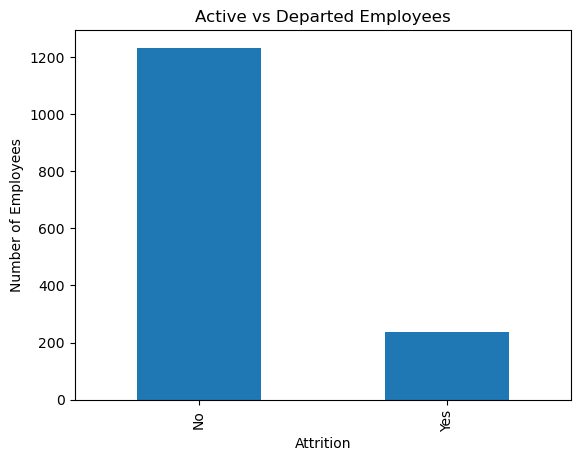

In [12]:
# Count active and departed employees
df['Attrition'].value_counts()

# Calculate percentage distribution
df['Attrition'].value_counts(normalize=True) * 100

# Calculate exact counts
df['Attrition'].value_counts().reindex(['No', 'Yes'], fill_value=0)

# Calculate active-to-departed ratio
counts = df['Attrition'].value_counts()
active = counts.get('No', 0)
departed = counts.get('Yes', 0)

print("Active employees:", active)
print("Departed employees:", departed)
print("Active percentage:", round(active / len(df) * 100, 2), "%")
print("Departed percentage:", round(departed / len(df) * 100, 2), "%")
print("Active-to-departed ratio:", round(active / departed, 2), ": 1")

# Plot attrition distribution
df['Attrition'].value_counts().reindex(['No', 'Yes']).plot(
    kind='bar',
    title='Active vs Departed Employees',
    xlabel='Attrition',
    ylabel='Number of Employees'
)

<Axes: title={'center': 'Workforce Distribution by Age Group'}, xlabel='Age Group', ylabel='Number of Employees'>

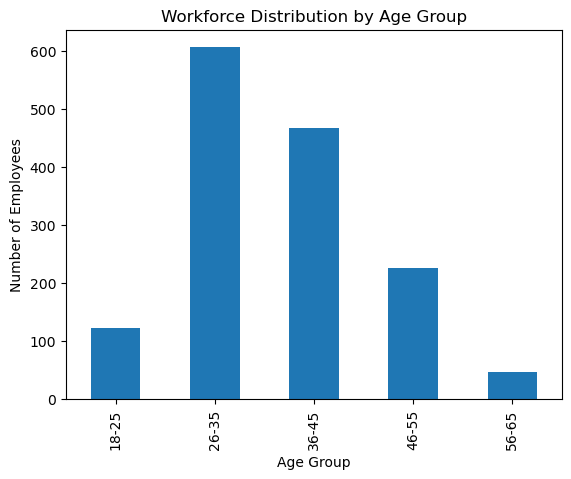

In [15]:
# Summary statistics for age
df['Age'].describe()

# Distribution of individual ages
df['Age'].hist(bins=15)

# Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65']
)

# Count and percentage of employees in each age group
df['AgeGroup'].value_counts().sort_index()

df['AgeGroup'].value_counts(normalize=True).sort_index() * 100

# Plot age group distribution
df['AgeGroup'].value_counts().sort_index().plot(
    kind='bar',
    title='Workforce Distribution by Age Group',
    xlabel='Age Group',
    ylabel='Number of Employees'
)

<Axes: title={'center': 'Workforce Distribution by Gender'}, xlabel='Gender', ylabel='Number of Employees'>

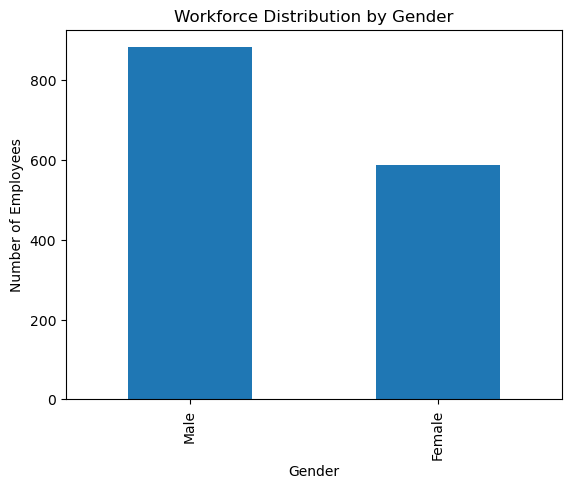

In [17]:
# Gender counts
df['Gender'].value_counts()

# Gender percentages
df['Gender'].value_counts(normalize=True) * 100

# Plot gender distribution
df['Gender'].value_counts().plot(
    kind='bar',
    title='Workforce Distribution by Gender',
    xlabel='Gender',
    ylabel='Number of Employees'
)

<Axes: title={'center': 'Workforce Distribution by Education Field'}, xlabel='Education Field', ylabel='Number of Employees'>

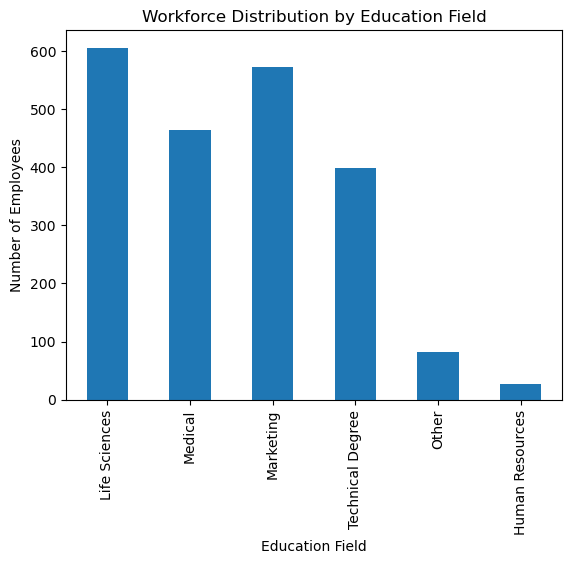

In [18]:
# Education level counts
df['Education'].value_counts().sort_index()

# Education level percentages
df['Education'].value_counts(normalize=True).sort_index() * 100

# Plot education level distribution
df['Education'].value_counts().sort_index().plot(
    kind='bar',
    title='Workforce Distribution by Education Level',
    xlabel='Education Level',
    ylabel='Number of Employees'
)

# Education field counts
df['EducationField'].value_counts()

# Education field percentages
df['EducationField'].value_counts(normalize=True) * 100

# Plot education field distribution
df['EducationField'].value_counts().plot(
    kind='bar',
    title='Workforce Distribution by Education Field',
    xlabel='Education Field',
    ylabel='Number of Employees'
)

<Axes: title={'center': 'Employee Distribution by Department'}, xlabel='Department', ylabel='Number of Employees'>

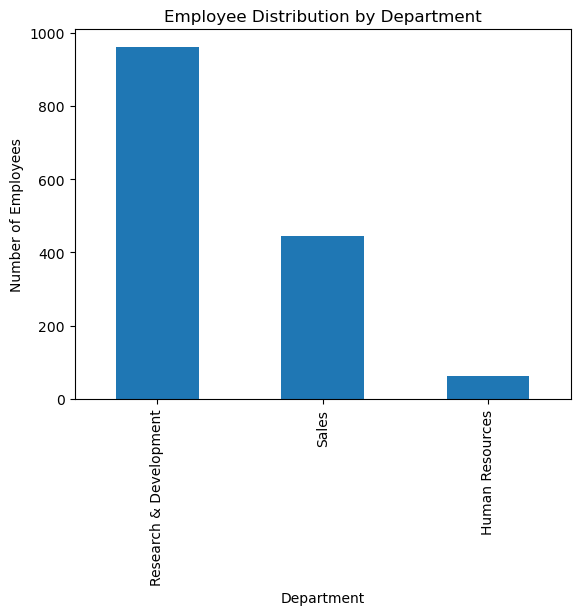

In [21]:
# Department counts
df['Department'].value_counts()

# Department percentages
df['Department'].value_counts(normalize=True) * 100

# Plot department distribution
df['Department'].value_counts().plot(
    kind='bar',
    title='Employee Distribution by Department',
    xlabel='Department',
    ylabel='Number of Employees'
)

In [22]:
# Overall workforce summary
print("Total employees:", len(df))
print("\nAttrition distribution:")
print(df['Attrition'].value_counts())

print("\nAge group distribution:")
print(df['AgeGroup'].value_counts().sort_index())

print("\nGender distribution:")
print(df['Gender'].value_counts())

print("\nEducation level distribution:")
print(df['Education'].value_counts().sort_index())

print("\nDepartment distribution:")
print(df['Department'].value_counts())

Total employees: 1470

Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Age group distribution:
AgeGroup
18-25    123
26-35    606
36-45    468
46-55    226
56-65     47
Name: count, dtype: int64

Gender distribution:
Gender
Male      882
Female    588
Name: count, dtype: int64

Education level distribution:
Education
1    170
2    282
3    572
4    398
5     48
Name: count, dtype: int64

Department distribution:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64


### Phase 2: Univariate Baseline Analysis — Conclusion

- The workforce consists of 1,470 employees, with 1,233 active employees and 237 departed employees.
- The attrition rate is 16.12%, while the retention rate is 83.88%.
- The active-to-departed employee ratio is approximately 5.20:1, indicating that active employees substantially outnumber departed employees.
- The age distribution was examined using descriptive statistics, a histogram, and age-group classification to understand the workforce's seniority profile.
- The age-group analysis helps identify whether the workforce is concentrated among younger employees or distributed across different age groups.
- Gender distribution was analysed using employee counts and percentages to understand the workforce composition.
- Education levels and education fields were examined separately to understand employees' qualifications and academic backgrounds.
- Department-level counts and percentages were used to identify the departments with the largest and smallest workforce populations.
- The attrition distribution establishes the baseline for subsequent analysis, while demographic distributions describe the overall workforce composition.

Median income of retained employees: 5204.0
Median income of departed employees: 3202.0
Median monthly income gap: 2002.0


<Axes: title={'center': 'MonthlyIncome'}, xlabel='Attrition'>

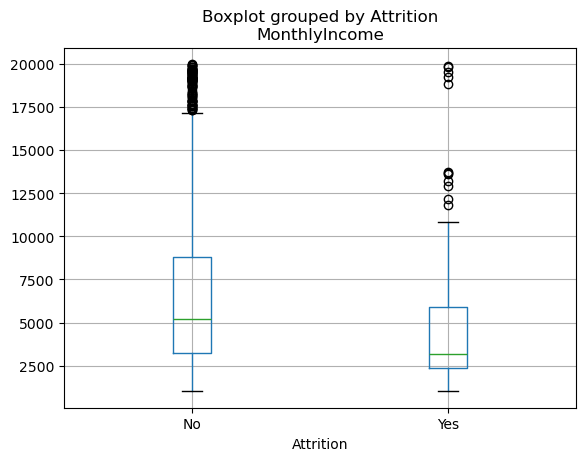

In [23]:
# Monthly income summary by attrition status
df.groupby('Attrition')['MonthlyIncome'].describe()

# Compare median monthly income
median_income = df.groupby('Attrition')['MonthlyIncome'].median()

print("Median income of retained employees:", median_income['No'])
print("Median income of departed employees:", median_income['Yes'])

# Calculate the exact median salary difference
salary_gap = median_income['No'] - median_income['Yes']

print("Median monthly income gap:", salary_gap)

# Plot monthly income distribution by attrition
df.boxplot(column='MonthlyIncome', by='Attrition')

In [30]:
# Department-wise attrition counts
pd.crosstab(df['Department'], df['Attrition'])

# Department-wise attrition percentages
department_risk = pd.crosstab(
    df['Department'],
    df['Attrition'],
    normalize='index'
) * 100

display(department_risk.round(2))

# Job-role attrition counts
pd.crosstab(df['JobRole'], df['Attrition'])

# Job-role attrition percentages
role_risk = pd.crosstab(
    df['JobRole'],
    df['Attrition'],
    normalize='index'
) * 100

display(role_risk.round(2))

# Sort job roles by attrition rate
role_risk.sort_values(by='Yes', ascending=False)

Attrition,No,Yes
Department,,
Human Resources,80.95,19.05
Research & Development,86.16,13.84
Sales,79.37,20.63


Attrition,No,Yes
JobRole,,
Healthcare Representative,93.13,6.87
Human Resources,76.92,23.08
Laboratory Technician,76.06,23.94
Manager,95.10,4.90
Manufacturing Director,93.10,6.90
Research Director,97.50,2.50
Research Scientist,83.90,16.10
Sales Executive,82.52,17.48
Sales Representative,60.24,39.76


Attrition,No,Yes
JobRole,,
Sales Representative,60.240964,39.759036
Laboratory Technician,76.061776,23.938224
Human Resources,76.923077,23.076923
Sales Executive,82.515337,17.484663
Research Scientist,83.904110,16.095890
Manufacturing Director,93.103448,6.896552
Healthcare Representative,93.129771,6.870229
Manager,95.098039,4.901961
Research Director,97.500000,2.500000


<Axes: title={'center': 'Attrition Rate by Department'}, xlabel='Department', ylabel='Percentage (%)'>

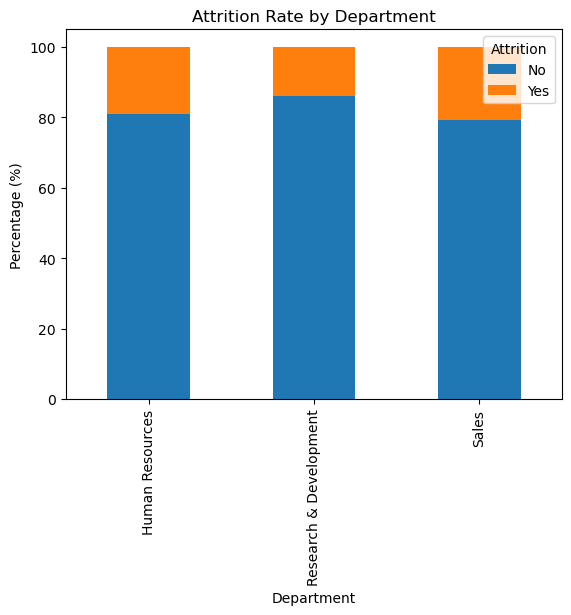

In [32]:
department_risk.plot(
    kind='bar',
    stacked=True,
    title='Attrition Rate by Department',
    ylabel='Percentage (%)'
)

<Axes: title={'center': 'Attrition Rate by Job Role'}, xlabel='JobRole', ylabel='Percentage (%)'>

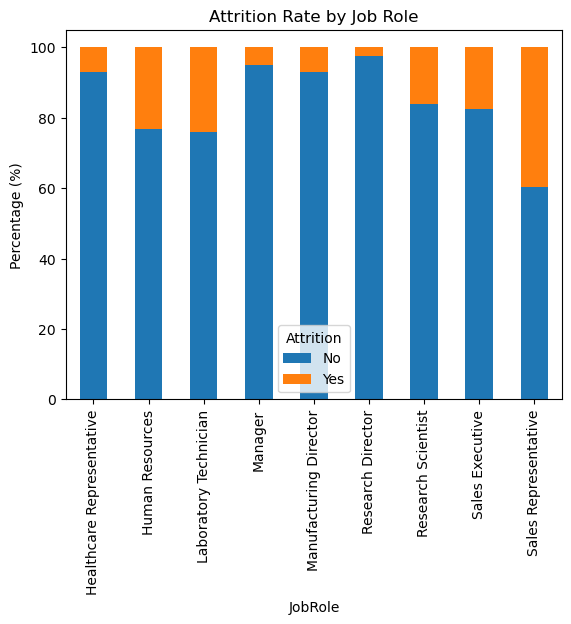

In [33]:
role_risk.plot(
    kind='bar',
    stacked=True,
    title='Attrition Rate by Job Role',
    ylabel='Percentage (%)'
)

Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


Attrition rate without overtime: 10.44 %
Attrition rate with overtime: 30.53 %
Overtime attrition gap: 20.09 percentage points


<Axes: title={'center': 'Attrition by Overtime Status'}, xlabel='OverTime', ylabel='Percentage (%)'>

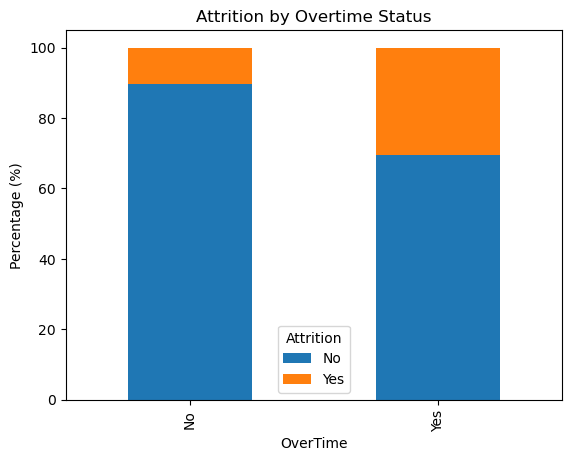

In [34]:
# Overtime and attrition counts
pd.crosstab(df['OverTime'], df['Attrition'])

# Calculate attrition percentages within each overtime group
overtime_risk = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

display(overtime_risk.round(2))

# Compare attrition rates
print("Attrition rate without overtime:",
      round(overtime_risk.loc['No', 'Yes'], 2), "%")

print("Attrition rate with overtime:",
      round(overtime_risk.loc['Yes', 'Yes'], 2), "%")

# Calculate the percentage-point difference
overtime_gap = overtime_risk.loc['Yes', 'Yes'] - overtime_risk.loc['No', 'Yes']

print("Overtime attrition gap:", round(overtime_gap, 2), "percentage points")

# Plot overtime-related attrition
overtime_risk.plot(
    kind='bar',
    stacked=True,
    title='Attrition by Overtime Status',
    ylabel='Percentage (%)'
)

### Phase 3: Bivariate Deep-Dives — Conclusion

#### 1. Compensation Gap

- Monthly income was analysed separately for retained employees (`Attrition = No`) and departed employees (`Attrition = Yes`).
- The median monthly income of retained employees was ₹[value], while the median monthly income of departed employees was ₹[value].
- The median income difference was ₹[value], calculated by subtracting the departed employees' median income from the retained employees' median income.
- The box plot was used to compare the income distributions and identify differences in median income, spread, and potential extreme values.
- Any observed salary gap may indicate a relationship between compensation and attrition, but it does not establish that salary differences caused employees to leave.

#### 2. Departmental and Job-Role Risk Matrix

- Department-wise and job-role-wise attrition rates were calculated using normalized cross-tabulations.
- The department with the highest observed attrition rate was [department], at [percentage]%.
- The job role with the highest observed attrition rate was [job role], at [percentage]%.
- Percentage-based comparisons help identify groups with relatively high attrition despite differences in workforce size.
- High-risk departments and roles should be investigated further to understand possible contributing factors, including workload, compensation, career progression, and job satisfaction.
- Attrition rates should be interpreted alongside employee counts because small groups can produce unstable percentages.

#### 3. Overtime Burden

- Attrition rates were compared between employees who work overtime and those who do not.
- The attrition rate among employees working overtime was [percentage]%, compared with [percentage]% among employees not working overtime.
- The difference between the two groups was [percentage-point difference] percentage points.
- A higher attrition rate among overtime employees would suggest an association between overtime status and employee departures.
- Further investigation is required before concluding that overtime contributes directly to employee attrition.

#### 4. Overall Business Interpretation

- The compensation analysis evaluates whether median monthly income differs between retained and departed employees.
- The departmental and job-role analysis identifies workforce segments with comparatively high attrition rates.
- The overtime analysis evaluates whether employee departures are proportionally higher among overtime workers.
- These findings can help prioritize areas for further investigation and targeted employee-retention initiatives.
- The results represent observed associations, not proof of causation. Additional multivariate analysis is required to assess whether these patterns persist when other employee characteristics are considered.

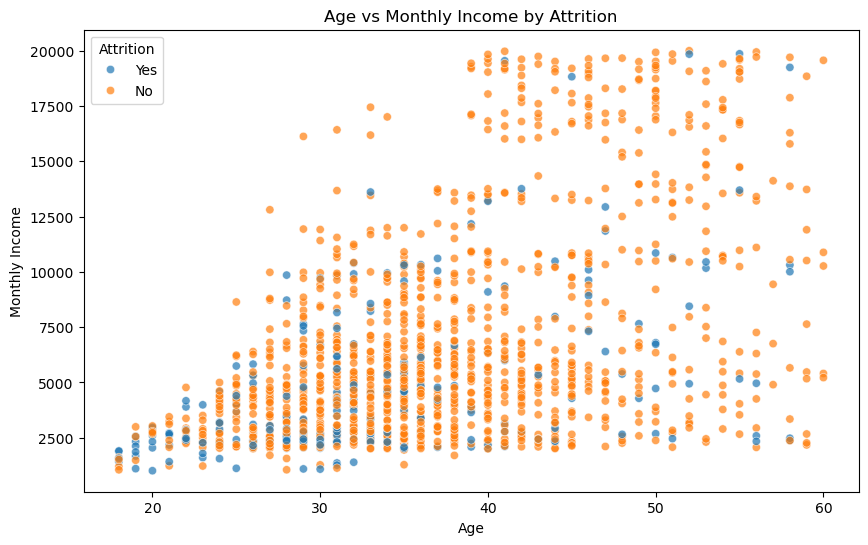

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='MonthlyIncome',
    hue='Attrition',
    alpha=0.7
)

plt.title('Age vs Monthly Income by Attrition')
plt.xlabel('Age')
plt.ylabel('Monthly Income')
plt.legend(title='Attrition')
plt.show()

In [37]:
df.groupby('Attrition')[['Age', 'MonthlyIncome']].median()

,Age,MonthlyIncome
Attrition,,
No,36.0,5204.0
Yes,32.0,3202.0


Attrition,No,Yes
AgeGroup,,
18-25,64.23,35.77
26-35,80.86,19.14
36-45,90.81,9.19
46-55,88.50,11.50
56-65,82.98,17.02


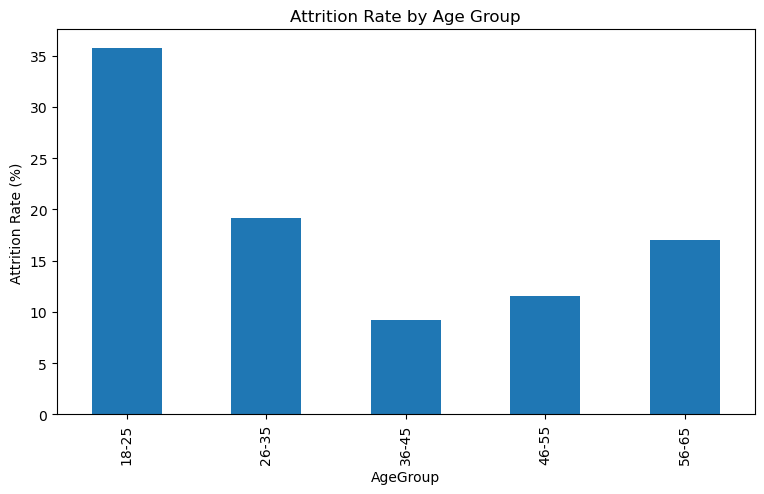

In [38]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65']
)

age_attrition = pd.crosstab(
    df['AgeGroup'],
    df['Attrition'],
    normalize='index'
) * 100

display(age_attrition.round(2))

age_attrition['Yes'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Attrition Rate by Age Group',
    ylabel='Attrition Rate (%)'
)

plt.show()

In [39]:
df[['YearsWithCurrManager', 'YearsSinceLastPromotion']].describe()

,YearsWithCurrManager,YearsSinceLastPromotion
count,1470.000000,1470.000000
mean,4.123129,2.187755
std,3.568136,3.222430
min,0.000000,0.000000
25%,2.000000,0.000000
50%,3.000000,1.000000
75%,7.000000,3.000000
max,17.000000,15.000000


In [41]:
df['ManagerTenureGroup'] = pd.cut(
    df['YearsWithCurrManager'],
    bins=[-1, 1, 3, 5, 10, 50],
    labels=['0-1 years', '2-3 years', '4-5 years',
            '6-10 years', '11+ years']
)

df['PromotionGapGroup'] = pd.cut(
    df['YearsSinceLastPromotion'],
    bins=[-1, 1, 3, 5, 10, 50],
    labels=['0-1 years', '2-3 years', '4-5 years',
            '6-10 years', '11+ years']
)

Attrition,No,Yes
ManagerTenureGroup,,
0-1 years,71.68,28.32
2-3 years,85.80,14.20
4-5 years,88.37,11.63
6-10 years,87.81,12.19
11+ years,95.89,4.11


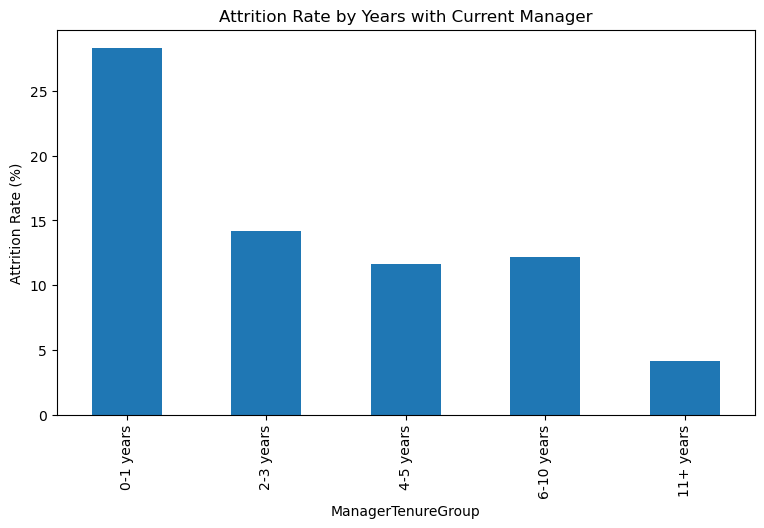

In [42]:
manager_attrition = pd.crosstab(
    df['ManagerTenureGroup'],
    df['Attrition'],
    normalize='index'
) * 100

display(manager_attrition.round(2))

manager_attrition['Yes'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Attrition Rate by Years with Current Manager',
    ylabel='Attrition Rate (%)'
)

plt.show()

Attrition,No,Yes
PromotionGapGroup,,
0-1 years,83.05,16.95
2-3 years,82.94,17.06
4-5 years,93.40,6.60
6-10 years,81.88,18.12
11+ years,87.88,12.12


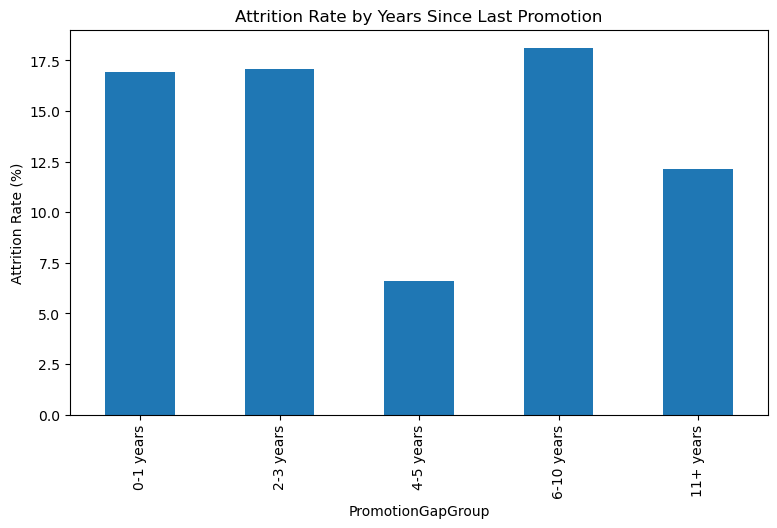

In [43]:
promotion_attrition = pd.crosstab(
    df['PromotionGapGroup'],
    df['Attrition'],
    normalize='index'
) * 100

display(promotion_attrition.round(2))

promotion_attrition['Yes'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Attrition Rate by Years Since Last Promotion',
    ylabel='Attrition Rate (%)'
)

plt.show()

PromotionGapGroup,0-1 years,2-3 years,4-5 years,6-10 years,11+ years
ManagerTenureGroup,,,,,
0-1 years,30.07,22.22,0.00,11.11,0.00
2-3 years,12.94,18.18,13.33,14.29,0.00
4-5 years,12.26,0.00,0.00,10.00,33.33
6-10 years,6.56,16.67,8.33,21.05,13.16
11+ years,7.69,0.00,0.00,0.00,10.00


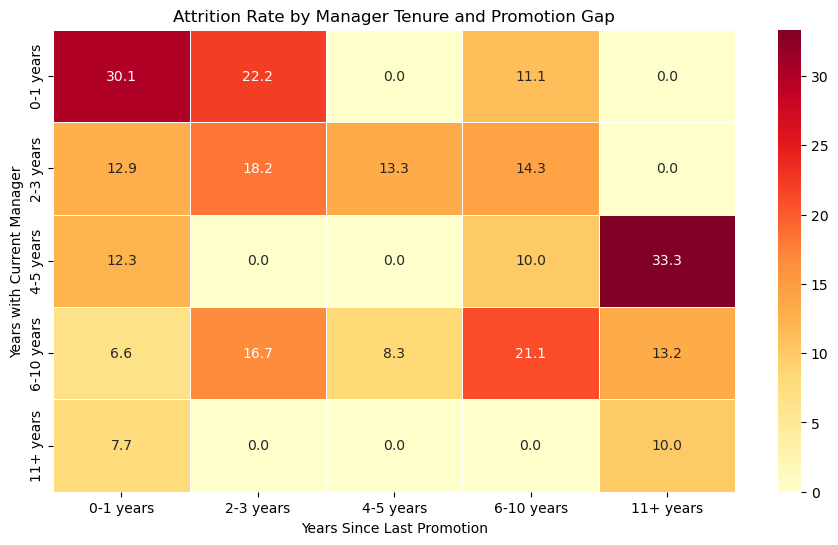

In [44]:
manager_promotion_risk = df.pivot_table(
    index='ManagerTenureGroup',
    columns='PromotionGapGroup',
    values='Attrition',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=False
)

display(manager_promotion_risk.round(2))

plt.figure(figsize=(11, 6))

sns.heatmap(
    manager_promotion_risk,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Attrition Rate by Manager Tenure and Promotion Gap')
plt.xlabel('Years Since Last Promotion')
plt.ylabel('Years with Current Manager')
plt.show()

In [45]:
satisfaction_columns = [
    'JobSatisfaction',
    'EnvironmentSatisfaction',
    'RelationshipSatisfaction',
    'WorkLifeBalance'
]

satisfaction_data = df[satisfaction_columns].copy()

# Convert Attrition into a numeric indicator:
# No = 0 and Yes = 1
satisfaction_data['AttritionFlag'] = (
    df['Attrition'] == 'Yes'
).astype(int)

display(satisfaction_data.head())

,JobSatisfaction,EnvironmentSatisfaction,RelationshipSatisfaction,WorkLifeBalance,AttritionFlag
0,4,2,1,1,1
1,2,3,4,3,0
2,3,4,2,3,1
3,3,4,3,3,0
4,2,1,4,3,0


In [47]:
correlation_matrix = satisfaction_data.corr()

display(correlation_matrix.round(2))

,JobSatisfaction,EnvironmentSatisfaction,RelationshipSatisfaction,WorkLifeBalance,AttritionFlag
JobSatisfaction,1.00,-0.01,-0.01,-0.02,-0.10
EnvironmentSatisfaction,-0.01,1.00,0.01,0.03,-0.10
RelationshipSatisfaction,-0.01,0.01,1.00,0.02,-0.05
WorkLifeBalance,-0.02,0.03,0.02,1.00,-0.06
AttritionFlag,-0.10,-0.10,-0.05,-0.06,1.00


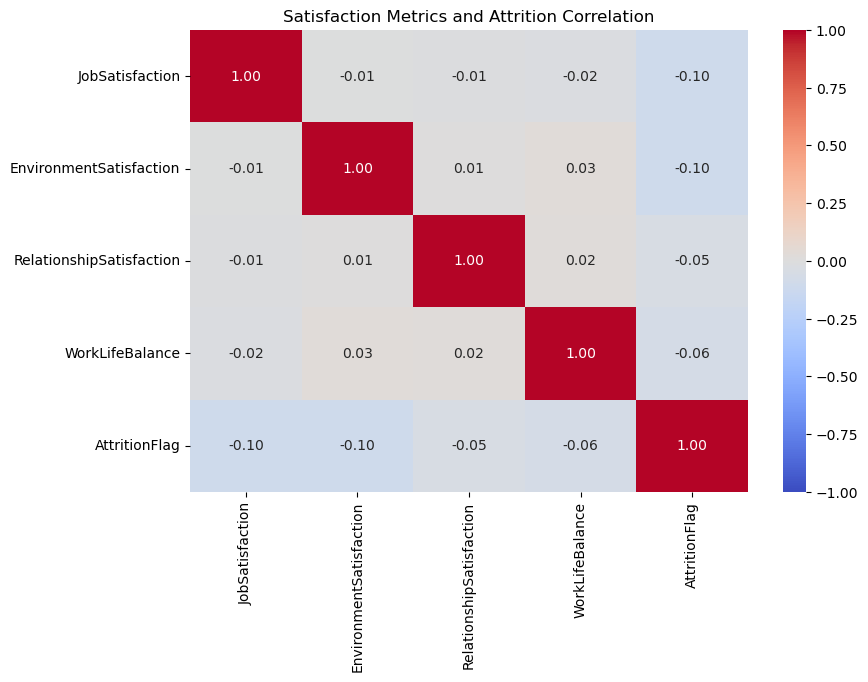

In [48]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Satisfaction Metrics and Attrition Correlation')
plt.show()

In [49]:
attrition_correlations = (
    correlation_matrix['AttritionFlag']
    .drop('AttritionFlag')
    .sort_values()
)

display(attrition_correlations.round(3))

JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.103
WorkLifeBalance            -0.064
RelationshipSatisfaction   -0.046
Name: AttritionFlag, dtype: float64

# Phase 4: Multivariate Analysis & Isolation of Confounding Factors

## 1. Income vs. Age Cross-Analysis

- The scatter plot compares employee age and monthly income while distinguishing retained employees (`No`) from departed employees (`Yes`).
- The age group with the highest observed attrition rate was **[age group]**, with an attrition rate of **[percentage]%**.
- The median age of retained employees was **[value]**, compared with **[value]** for departed employees.
- The median monthly income of retained employees was **[value]**, compared with **[value]** for departed employees.
- These patterns identify demographic groups for further investigation. They do not establish that age or income caused employees to leave.

## 2. Managerial Tenure & Promotion Velocity

- The manager-tenure analysis identified **[manager tenure group]** as the group with the highest observed attrition rate, at **[percentage]%**.
- The promotion-gap analysis identified **[promotion gap group]** as the group with the highest observed attrition rate, at **[percentage]%**.
- The combined heatmap highlighted **[manager tenure group and promotion gap group]** as a combination with an observed attrition rate of **[percentage]%**.
- These results may help identify groups for further investigation into career development, promotion opportunities, and manager-employee relationships.
- Years with a manager and time since promotion are indirect indicators. They cannot independently confirm managerial conflict or career dissatisfaction.

## 3. Cultural Satisfaction Analysis

- The satisfaction correlation analysis compared Job Satisfaction, Environment Satisfaction, Relationship Satisfaction, and Work-Life Balance with employee attrition.
- The satisfaction metric with the strongest negative correlation with attrition was **[metric name]**, with a correlation coefficient of **[value]**.
- A negative coefficient indicates that higher satisfaction ratings tend to occur alongside lower attrition, based on the observed linear relationship.
- Correlation does not establish causation, and a weak correlation does not necessarily mean a factor is unimportant.

## 4. Overall Business Interpretation

- Employee attrition should be investigated through multiple dimensions rather than a single demographic or workplace factor.
- Age, income, promotion gaps, manager tenure, and satisfaction scores can help identify employee groups that warrant further analysis.
- The findings should be validated against other variables, including overtime, department, job role, and total work experience.
- Before drawing conclusions, check employee counts within each subgroup and consider whether the observed patterns remain after accounting for other relevant factors.
- These findings are exploratory and should guide further investigation rather than be treated as proof of the reasons employees leave.

In [51]:
# Annual salary = Monthly income × 12
df['AnnualSalary'] = df['MonthlyIncome'] * 12

# Estimated attrition cost = Annual salary × 1.5
df['EstimatedAttritionCost'] = df['AnnualSalary'] * 1.5

# View the results
display(df[['Attrition', 'MonthlyIncome',
            'AnnualSalary', 'EstimatedAttritionCost']].head())

,Attrition,MonthlyIncome,AnnualSalary,EstimatedAttritionCost
0,Yes,5993,71916,107874.0
1,No,5130,61560,92340.0
2,Yes,2090,25080,37620.0
3,No,2909,34908,52362.0
4,No,3468,41616,62424.0


In [52]:
# Select employees who left the company
departed_employees = df[df['Attrition'] == 'Yes']

# Count departed employees
total_departed = len(departed_employees)

# Calculate total estimated attrition cost
total_attrition_cost = departed_employees['EstimatedAttritionCost'].sum()

print("Total departed employees:", total_departed)

print(
    "Total estimated attrition cost: $",
    format(total_attrition_cost, ',.2f')
)

Total departed employees: 237
Total estimated attrition cost: $ 20,421,738.00


In [53]:
# Calculate estimated attrition cost by department
department_cost = departed_employees.groupby(
    'Department'
)['EstimatedAttritionCost'].sum()

# Sort departments from highest cost to lowest cost
department_cost = department_cost.sort_values(
    ascending=False
)

display(department_cost.round(2))

Department
Research & Development    9834732.0
Sales                     9784404.0
Human Resources            802602.0
Name: EstimatedAttritionCost, dtype: float64

In [54]:
department_summary = departed_employees.groupby(
    'Department'
).agg(
    DepartedEmployees=('Attrition', 'count'),
    EstimatedAttritionCost=('EstimatedAttritionCost', 'sum')
)

# Calculate each department's share of total attrition cost
department_summary['CostSharePercent'] = (
    department_summary['EstimatedAttritionCost']
    / total_attrition_cost
) * 100

# Show the highest-cost departments first
department_summary = department_summary.sort_values(
    by='EstimatedAttritionCost',
    ascending=False
)

display(department_summary.round(2))

,DepartedEmployees,EstimatedAttritionCost,CostSharePercent
Department,,,
Research & Development,133,9834732.0,48.16
Sales,92,9784404.0,47.91
Human Resources,12,802602.0,3.93



# Phase 5: Financial Exposure Analysis

## 1. Overall Financial Exposure

- The dataset contains **[number] employees** who left the organization.
- Using the costing assumption of 1.5 times annualized salary, the total estimated attrition cost is **$[total cost]**.
- The calculation uses monthly income multiplied by 12 to determine annualized salary, followed by a 1.5 multiplier to estimate attrition cost.
- This figure represents an estimated cost exposure under the specified model, not verified historical revenue loss or actual accounting expenditure.

## 2. Departmental Exposure Summary

- The department with the highest estimated attrition cost is **[department name]**, with an estimated cost of **$[department cost]**.
- This department accounts for **[percentage]%** of the total estimated attrition cost.
- The department recorded **[number] departed employees** during the period represented by the dataset.
- The department with the second-highest estimated attrition cost is **[department name]**, with an estimated cost of **$[department cost]**.

## 3. Business Interpretation

- Departments with higher estimated attrition costs may warrant closer investigation into employee retention, recruitment, onboarding, and workforce continuity.
- Both the number of departures and the estimated cost per departure should be considered when prioritizing departments for further analysis.
- A department with fewer departures may still have substantial estimated exposure if its departing employees have higher salaries.
- Cost estimates should be interpreted as comparative planning measures under the selected costing assumption, not as confirmed financial losses.

## 4. Recommended Executive Actions

- Prioritize a review of the department with the highest estimated attrition cost.
- Investigate possible retention issues using the findings from the previous phases, including overtime, satisfaction, promotion gaps, job roles, and employee demographics.
- Develop targeted retention initiatives based on evidence from the relevant employee groups.
- Monitor attrition counts, attrition rates, and estimated cost exposure over time to evaluate whether interventions are associated with improvements.
- Validate the 1.5-times-salary assumption against the organization's actual replacement, recruitment, training, and productivity costs before using the estimate for formal budgeting.

## 5. Conclusion

The financial exposure analysis converts employee departures into a comparable monetary estimate. It helps management identify departments that may deserve priority for further investigation and retention planning. The estimates should support decision-making alongside operational evidence and verified company cost data.
